# Conexiones imposibles 01: ¿encontrarán los datos el vínculo?

**Categoría: EDA (análisis exploratorio de datos).**

Quiero saber qué tienen en común *Cazafantasmas 2* (1989) y *The Many Adventures of Winnie the Pooh* (1977). Primero comparo ficha técnica, géneros, etiquetas, créditos y 32 millones de valoraciones de MovieLens. Después confronto lo que esos datos encuentran con un detalle visual dentro de la película. No genero predicciones.

## Ruta de lectura y glosario

1. Sitúo ambas películas dentro del catálogo. 2. Comparo sus públicos. 3. Busco géneros y etiquetas compartidos. 4. Recorro los créditos. 5. Explico qué queda fuera.

- **Percentil de popularidad:** porcentaje de películas con menos valoraciones.
- **Correlación:** indica si dos conjuntos de notas tienden a subir y bajar juntos; 0 significa que apenas lo hacen.
- **Ruta:** sucesión de películas y profesionales unidos por créditos.

## Fuentes y unidad de análisis

Uso MovieLens 32M, con 32.000.204 valoraciones sobre 84.432 películas hasta el 12 de octubre de 2023. Cada fila de `valoraciones_compartidas.csv` es una persona que puntuó ambas obras. Completo la ficha con Disney, Sony y Wikidata, y analizo ocho clases de créditos. MovieLens recoge a sus usuarios, no a todo el público mundial. Wikidata es colaborativa y puede omitir créditos.

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import pandas as pd

# cargo los resultados comprobados y mantengo los datos separados del análisis
ruta_base = Path('.')
ficha = pd.read_csv(ruta_base / 'ficha_tecnica.csv')
compartidas = pd.read_csv(ruta_base / 'valoraciones_compartidas.csv')
rutas = pd.read_csv(ruta_base / 'rutas_wikidata.csv')
with (ruta_base / 'resultados_movielens.json').open(encoding='utf-8') as archivo:
    resultados = json.load(archivo)
ficha

,pelicula,estreno,duracion_minutos,clasificacion,valoraciones_movielens,media_movielens,mediana_movielens,percentil_popularidad,reparto_o_voces,directores,guionistas,productores,compositores,montadores
0,Cazafantasmas 2,1989,108,PG,10171,3.050,3.0,99.10,21,1,2,4,1,1
1,The Many Adventures of Winnie the Pooh,1977,75,G,788,3.687,4.0,94.09,15,2,9,1,3,2


## Dos fichas que empiezan separadas

Las películas están separadas por 12 años y 33 minutos. MovieLens asigna a *Cazafantasmas 2* comedia, fantasía y ciencia ficción; a Pooh, animación, cine infantil y musical. No comparten ningún género de los seis registrados. La comparación no parte de dos obras parecidas.

In [2]:
# compruebo las diferencias básicas antes de buscar semejanzas más complejas
diferencias_basicas = {
    'años_de_diferencia': int(ficha['estreno'].max() - ficha['estreno'].min()),
    'minutos_de_diferencia': int(ficha['duracion_minutos'].max() - ficha['duracion_minutos'].min()),
    'generos_compartidos': resultados['generos_compartidos'],
}
diferencias_basicas

{'años_de_diferencia': 12, 'minutos_de_diferencia': 33, 'generos_compartidos': []}

## Las dos son populares, pero no a la misma escala

El percentil no compara la calidad. Solo sitúa el número de valoraciones dentro del catálogo: estar en el 99,1 significa que el 99,1% de las películas tiene menos votos.

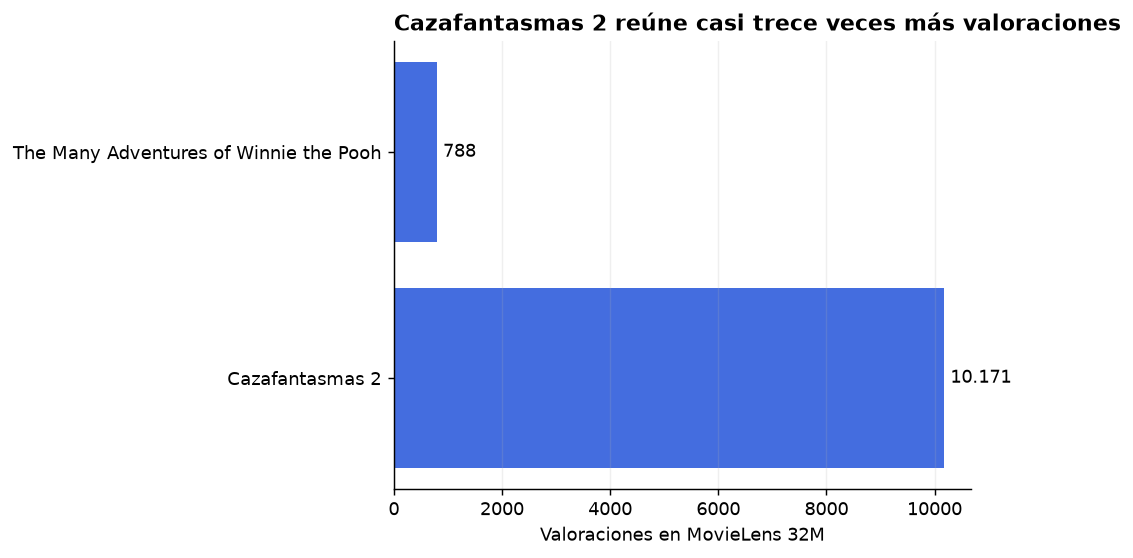

In [3]:
# dibujo la popularidad relativa sin confundirla con la nota
color_principal = '#446ddf'
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(ficha['pelicula'], ficha['valoraciones_movielens'], color=color_principal)
ax.set_title('Cazafantasmas 2 reúne casi trece veces más valoraciones', loc='left', weight='bold')
ax.set_xlabel('Valoraciones en MovieLens 32M')
ax.set_ylabel('')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.2)
for indice, valor in enumerate(ficha['valoraciones_movielens']):
    ax.text(valor + 120, indice, f'{valor:,}'.replace(',', '.'), va='center')
plt.tight_layout()
plt.show()

*Cazafantasmas 2* suma 10.171 valoraciones y queda en el percentil 99,1. Pooh reúne 788, pero aun así supera al 94,09% del catálogo. La diferencia de visibilidad es grande; las dos están lejos de ser títulos desconocidos dentro de MovieLens.

## 277 espectadores forman el puente humano

Solo 277 usuarios puntuaron las dos películas. Son el 2,72% de quienes valoraron *Cazafantasmas 2*, pero el 35,15% de quienes valoraron Pooh. Entre esas personas, las notas tienen una correlación débil de 0,257: que alguien puntúe alto una no permite anticipar bien su nota para la otra.

In [4]:
# resumo el cruce de público sin extrapolarlo fuera de MovieLens
resumen_publico = pd.Series({
    'usuarios que puntuaron ambas': resultados['usuarios_compartidos'],
    'correlación entre notas': resultados['correlacion_entre_notas_compartidas'],
    'diferencia media en puntos': resultados['diferencia_absoluta_media'],
    'notas separadas como máximo por 0,5 puntos (%)': resultados['porcentaje_notas_a_medio_punto'],
})
resumen_publico

usuarios que puntuaron ambas                      277.000
correlación entre notas                             0.257
diferencia media en puntos                          0.913
notas separadas como máximo por 0,5 puntos (%)     48.740
dtype: float64

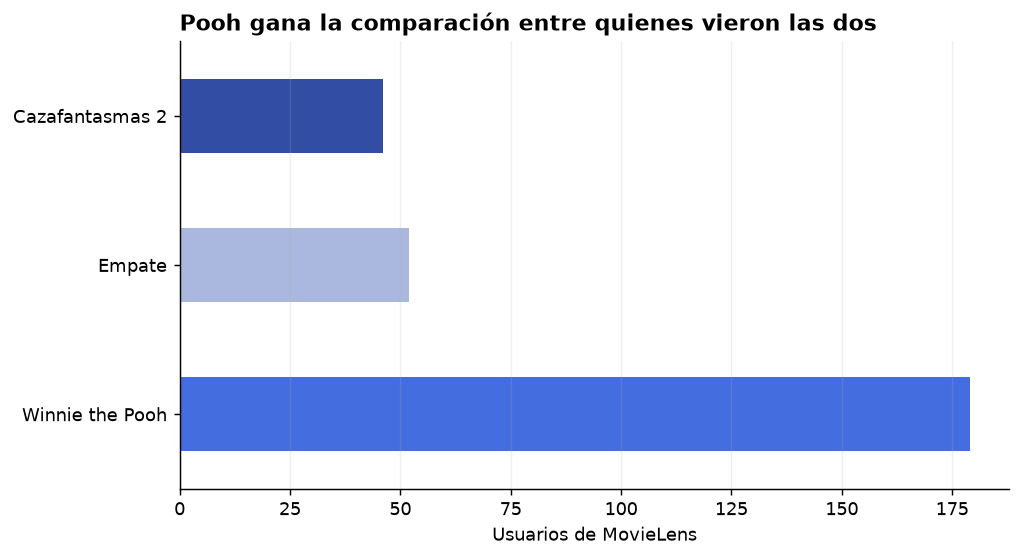

In [5]:
# comparo qué película prefirió cada persona que valoró las dos
preferencias = pd.Series(resultados['preferencias']).reindex(['Winnie the Pooh', 'Empate', 'Cazafantasmas 2'])
fig, ax = plt.subplots(figsize=(8, 4.4))
preferencias.plot.barh(ax=ax, color=['#446ddf', '#aab8df', '#314ea4'])
ax.set_title('Pooh gana la comparación entre quienes vieron las dos', loc='left', weight='bold')
ax.set_xlabel('Usuarios de MovieLens')
ax.set_ylabel('')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

De los 277 usuarios compartidos, 179 dieron más nota a Pooh, 46 a *Cazafantasmas 2* y 52 las puntuaron igual. En casi la mitad de los casos, las notas quedaron separadas por medio punto o menos. Comparten espectadores, pero no provocan exactamente la misma reacción.

## Ni los géneros ni las etiquetas encuentran el vínculo

MovieLens conserva 140 etiquetas para *Cazafantasmas 2* y 13 para Pooh. Después de normalizar mayúsculas, acentos y espacios, no aparece ninguna coincidencia exacta. Fantasmas, comedia y paranormal dominan una; Disney, dibujos animados y animales parlantes describen la otra.

In [6]:
# compruebo de forma explícita el solapamiento de géneros y etiquetas
solapamientos = {
    'géneros compartidos': len(resultados['generos_compartidos']),
    'etiquetas compartidas': len(resultados['etiquetas_compartidas']),
    'rutas de créditos con una película intermedia': len(rutas),
}
solapamientos

{'géneros compartidos': 0, 'etiquetas compartidas': 0, 'rutas de créditos con una película intermedia': 5}

## Los créditos sí construyen cinco rodeos

Wikidata encuentra cinco rutas de cuatro créditos. La más reconocible pasa por Rick Moranis, *Parenthood* y Clint Howard. Las demás atraviesan *Oliver y su pandilla*, *EDtv*, *The Cannonball Run* y *The Brave Little Toaster Goes to Mars*. Son conexiones válidas, pero todas necesitan otra película y dos profesionales.

In [7]:
# muestro las cinco rutas sin esconder los oficios que las sostienen
rutas[['persona_origen', 'rol_origen', 'pelicula_intermedia', 'persona_destino', 'rol_destino']]

,persona_origen,rol_origen,pelicula_intermedia,persona_destino,rol_destino
0,Rick Moranis,miembro del reparto,Parenthood,Clint Howard,actor de voz
1,Cheech Marín,miembro del reparto,Oliver y su pandilla,James Melton,editor de cine
2,Donn Cambern,editor de cine,The Cannonball Run,John Fiedler,actor de voz
3,Randy Edelman,compositor,EDtv,Clint Howard,actor de voz
4,Brian Doyle-Murray,miembro del reparto,The Brave Little Toaster Goes To Mars,Thurl Ravenscroft,actor de voz


## Comprobaciones y limitaciones

Compruebo 32.000.204 valoraciones y 84.432 películas, sin vacíos en las dos fichas analizadas. MovieLens no representa a toda la población y sus etiquetas son desiguales: 140 frente a 13. Wikidata puede omitir personas y clasificar reparto y voces de forma distinta. La duración de *Cazafantasmas 2* varía entre fuentes; utilizo los 108 minutos indicados por Sony. No analizo fotogramas automáticamente ni infiero la intención del vestuario.

## Conclusión

Los datos cuantifican una pareja improbable: cero géneros compartidos, cero etiquetas coincidentes, 277 espectadores comunes y cinco rutas que necesitan rodeos. Sin embargo, la conexión más corta está dentro de *Cazafantasmas 2*: Óscar lleva una prenda con Winnie the Pooh. El EDA no demuestra que los datos fallen. Demuestra qué saben registrar: créditos, categorías y decisiones de usuarios, pero no todos los pequeños detalles que aparecen en pantalla.